# Adaptive LTV for tokenized real estate: a fuzzy closed-loop controller

**Author:** Christophe Abelem — Inteligência Computacional, CESUPA, 2026

## Generative AI disclosure

<!-- TODO (Christophe): fill before delivery. The lauda requires at least the four items below. -->
- **Tool:**
- **Purpose:**
- **Approximate extent of the contribution:**
- **Validation measures:**

## How to run

1. `uv venv --python 3.12 && source .venv/bin/activate`
2. `uv pip install -e ".[dev]"` installs the `adaptive_ltv` package and the notebook tools.
3. Run `00_data_test.ipynb` once: it downloads and freezes the data in `data/`.
4. `pytest` checks the package; then run this notebook top to bottom.

All computation lives in the `adaptive_ltv` package; this notebook calls it and explains the results.

## 1. Introduction and problem

**The setting.** Tokenized real estate splits a rental property into digital tokens. Each token gives its holder a
share of the rent. Holders can also deposit their tokens in a lending pool and borrow stablecoins (digital dollars)
against them, the way a home owner borrows against a house.

**The decision.** The pool must decide how much to lend per dollar of collateral. This ratio is the **maximum LTV**
(loan-to-value). With a max LTV of 60%, a token worth US$ 100 allows a loan of up to US$ 60. If the collateral loses
value and the loan rises above a second limit (the liquidation threshold), the position is **liquidated**: the
collateral is sold to repay the lenders. If the sale does not cover the debt, the shortfall is **bad debt**, a loss
for whoever lent the money.

**The problem.** A fixed max LTV ignores the state of the market. RealT, the largest tokenized real estate platform
(about 700 Detroit properties), used a fixed 60% in its lending market (RMM). In 2025-2026 rent stopped being
paid, the pool ran out of cash and liquidations surged; RealT announced its liquidation on 2 July 2026. Detroit house
prices, however, were near their all-time high. A rule that only watches prices would not have reacted.

**Objective.** Build a closed-loop fuzzy controller that sets the max LTV each month from three signals (price
volatility, pool liquidity, rent coverage) and compare its bad debt with the fixed 60% rule in two scenarios: a
market shock (prices fall, as in 2007-2011) and an operational collapse (rent and liquidity fail, as with RealT).

**Why fuzzy inference.** Risk teams set these limits with expert rules stated in words ("if volatility is high and
liquidity is low, lend less"). The boundaries are gradual, not sharp: 9% volatility is not "safe" while 9.1% is
"risky". Fuzzy sets model exactly this, and the rule base stays readable by someone outside finance.

**Sources and hypotheses.** Detroit prices: FRED `DEXRNSA`. Pool liquidity: DefiLlama. Risk parameters and
liquidations: read on-chain from the RMM contracts on Gnosis Chain. Rent coverage and appraisal steps are stylized
from documented dates (rent escrow Jul 2025, suspension Feb 2026), because no public time series exists. The data test
is in `00_data_test.ipynb`.

### Glossary

| Term | Meaning in this project |
| --- | --- |
| Collateral | The property tokens a borrower deposits to secure the loan |
| Max LTV | Largest loan allowed per dollar of collateral; the **output** of the controller |
| Liquidation threshold | Loan-to-value at which a position is liquidated (70% on RealT) |
| Liquidation | Forced sale of collateral to repay a loan that crossed the threshold |
| Bad debt | Debt left unpaid after a liquidation sale; the measure of failure |
| Volatility | How much prices swing; high volatility means collateral can lose value fast |
| Pool utilization | Share of the pool's cash already lent out; at 100% lenders cannot withdraw |
| Rent coverage | Share of expected rent actually paid; low coverage means the asset stopped producing income |
| Appraisal | Periodic official valuation of the property, used as the price the pool sees |

## Setup

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from adaptive_ltv.inputs import (CRUNCH_START, rent_coverage_stylized, utilization_daily,
                                 utilization_signal, volatility_signal)
from adaptive_ltv.controller import FuzzyLTVController, build_rules
from adaptive_ltv.membership import (LTV_MAX, LTV_MIN, max_ltv_variable, rent_variable,
                                     utilization_variable, volatility_variable)
from adaptive_ltv.plots import LINE, SHADE, STYLE, pct_axis, plot_memberships

plt.rcParams.update(STYLE)

## 2. Input variables

### 2.1 Market volatility (Detroit house prices)

**What it measures.** How much Detroit house prices swing from month to month. High volatility means the collateral
(the property tokens) can lose value quickly, so a loan that is safe today may not be covered tomorrow.

**Source.** The S&P Cotality Case-Shiller index for Detroit (FRED series `DEXRNSA`): one number per month since
1991 that tracks the price of the same houses over time.

**Three corrections before using it:**

1. **Seasonality.** House prices rise every spring and fall every winter. That pattern is predictable, so it is
   not risk: each calendar month's average change is removed.
2. **Smoothing.** House price indices react slowly, because sale prices are agreed weeks before they are recorded:
   each month repeats part of the previous month's change. This hides how large the real swings are. The standard
   correction (Geltner) estimates how much of last month's change is repeated (the coefficient ρ, between 0 and 1)
   and removes it with the formula below.
3. **Rolling window.** Volatility is the standard deviation of the last 12 corrected monthly changes, scaled to a
   yearly figure (×√12). It is recomputed every month, which is what the controller reads.

Code: `adaptive_ltv/inputs.py` (`volatility_signal`).

```latex
r^{true}_t = \frac{r^{obs}_t - \rho \, r^{obs}_{t-1}}{1 - \rho}
```

In [ ]:
vol, info = volatility_signal()

print(f"AR(1) rho = {info['rho']:.3f}")
print(f"annualized vol, observed (SA): {info['vol_observed']:.1%}")
print(f"annualized vol, de-smoothed:   {info['vol_desmoothed']:.1%}")
print(f"rolling vol series: {vol.index.min():%Y-%m} to {vol.index.max():%Y-%m}, {len(vol)} months")

AR(1) rho = 0.725
annualized vol, observed (SA): 3.6%
annualized vol, de-smoothed:   9.1%
rolling vol series: 1992-02 to 2026-07, 414 months


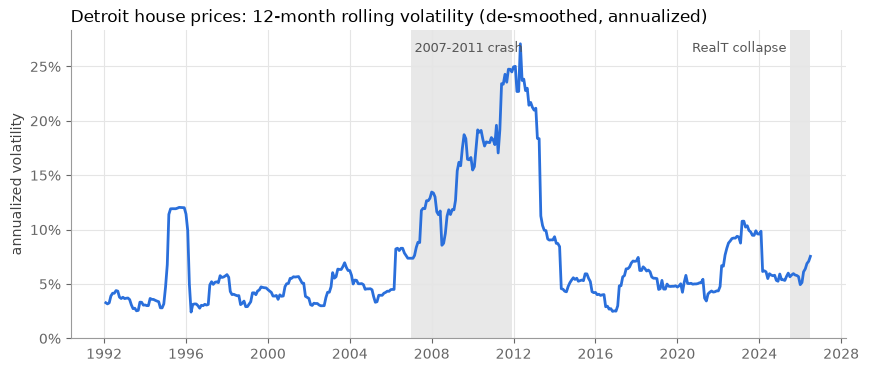

In [ ]:
fig, ax = plt.subplots()
for start, end in [("2007-01", "2011-12"), ("2025-07", "2026-07")]:
    ax.axvspan(pd.Timestamp(start), pd.Timestamp(end), color=SHADE, alpha=0.6, lw=0)
ax.plot(vol.index, vol, color=LINE, lw=2)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"{y:.0%}"))
ax.set_ylim(0, None)
ax.set_title("Detroit house prices: 12-month rolling volatility (de-smoothed, annualized)", loc="left")
ax.set_ylabel("annualized volatility")
ax.text(pd.Timestamp("2007-03"), ax.get_ylim()[1] * 0.93, "2007-2011 crash", color="#555555", fontsize=9)
ax.text(pd.Timestamp("2025-05"), ax.get_ylim()[1] * 0.93, "RealT collapse", color="#555555", fontsize=9, ha="right")
plt.show()

In [ ]:
vol_pct = vol.quantile([0.10, 0.25, 0.50, 0.75, 0.90, 0.95])
print(pd.DataFrame({"percentile": [f"p{int(q * 100)}" for q in vol_pct.index],
                    "vol": vol_pct.map("{:.1%}".format).values}).to_string(index=False))
print("\nRealT period:")
print(vol.loc["2025-06":].map("{:.1%}".format).to_string())

percentile   vol
       p10  3.2%
       p25  4.2%
       p50  5.5%
       p75  9.1%
       p90 16.6%
       p95 20.1%

RealT period:
date
2025-06-01    6.0%
2025-07-01    5.7%
2025-08-01    5.8%
2025-09-01    6.0%
2025-10-01    5.8%
2025-11-01    5.8%
2025-12-01    5.7%
2026-01-01    4.9%
2026-02-01    5.1%
2026-03-01    6.1%
2026-04-01    6.4%
2026-05-01    6.9%
2026-06-01    7.1%
2026-07-01    7.5%


**Interpretation.**

- **De-smoothing matters.** Removing the smoothing (ρ = 0.73: each month repeats about 73% of the previous month's change) raises yearly volatility from 3.6% to 9.1%. The raw index hides most of the risk.
- **The 2007-2011 crash dominates the series,** with a peak of 27%. The peak came in May 2012, about a year after prices bottomed in April 2011: a 12-month rolling window only rises once the large drops are inside it, so the signal lags the price move. For the controller, this means volatility may cut the LTV late in a market shock, which the simulation must test.
- **During the RealT collapse (Jul 2025 to Jul 2026) volatility stayed between 4.9% and 7.5%,** close to the historical median of 5.5%. Detroit prices gave no warning, so a controller driven only by price risk would not have reacted. This supports the operational-collapse side of the hypothesis: the signal has to come from rent and pool liquidity.

### 2.2 Volatility as a fuzzy variable

**Universe:** 0% to 30% annualized volatility (the historical maximum is 27%).
**Terms:** low, medium, high, as trapezoids. The breakpoints are the historical percentiles of the series above, so no
number is chosen by hand:

| Term | Breakpoints | Reading |
| --- | --- | --- |
| low | 0, 0, p25, p50 | fully low up to p25, no longer low at the median |
| medium | p25, p50, p75, p90 | fully medium between the median and p75 |
| high | p75, p90, 30%, 30% | starts at p75, fully high from p90 |

Adjacent terms cross so that the memberships always sum to 1: every volatility value is covered, with no gaps.

Code: `adaptive_ltv/membership.py` (`volatility_variable`).

In [ ]:
VOL = volatility_variable(vol)

print("breakpoints:", {t: [f"{x:.1%}" for x in pts] for t, pts in VOL.terms.items()})
cov = VOL.coverage()
print(f"membership sum over the universe: min {cov.min():.3f}, max {cov.max():.3f}")

for label, x in [("median", vol.median()), ("RealT period, max", vol.loc["2025-07":].max()), ("2012 peak", vol.max())]:
    print(f"{label:>18} ({x:.1%}):", {t: round(d, 2) for t, d in VOL.memberships(x).items()})

breakpoints: {'low': ['0.0%', '0.0%', '4.2%', '5.5%'], 'medium': ['4.2%', '5.5%', '9.1%', '16.6%'], 'high': ['9.1%', '16.6%', '30.0%', '30.0%']}
membership sum over the universe: min 1.000, max 1.000
            median (5.5%): {'low': 0.03, 'medium': 0.97, 'high': 0.0}
 RealT period, max (7.5%): {'low': 0.0, 'medium': 1.0, 'high': 0.0}
         2012 peak (27.1%): {'low': 0.0, 'medium': 0.0, 'high': 1.0}


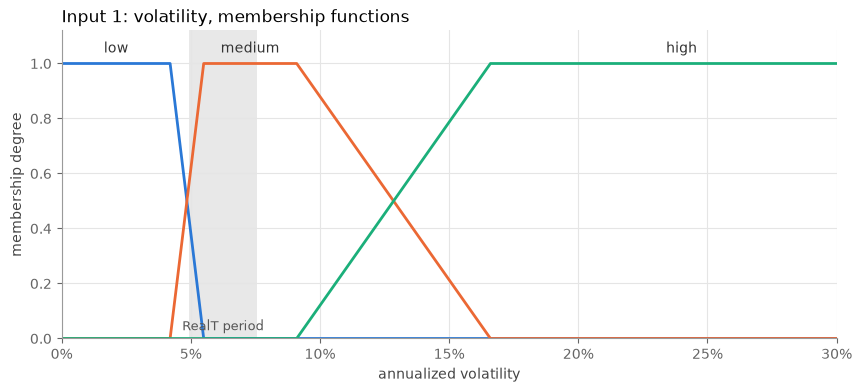

In [ ]:
realt = vol.loc["2025-07":]
plot_memberships(VOL, "Input 1: volatility, membership functions", "annualized volatility",
                 band=(realt.min(), realt.max()), band_label="RealT period", label_x={"high": 0.24})
plt.show()

**Reading.** The RealT period runs from 4.9% (about half "low", half "medium") to 7.5% (fully "medium"). The 2012 peak is fully
"high". Volatility alone would therefore keep the max LTV near its normal level during the RealT collapse.

### 2.3 Pool utilization

**What it measures.** The share of the pool's money already lent out: borrowed / (borrowed + idle cash). The pool holds stablecoins, digital tokens worth US$ 1 each that work as digital dollars.
At 100% the pool has no idle cash, so lenders cannot withdraw and new loans cannot be funded. Source: DefiLlama,
daily, averaged per month because the controller decides monthly. Code: `adaptive_ltv/inputs.py` (`utilization_signal`).

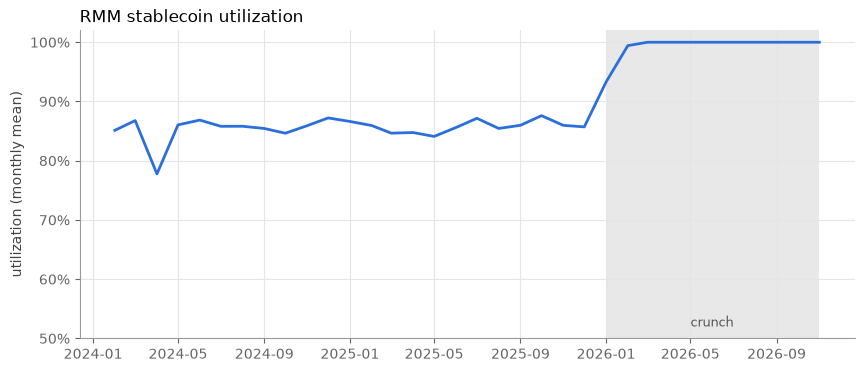

date
2025-06-01     85.6%
2025-07-01     87.2%
2025-08-01     85.4%
2025-09-01     86.0%
2025-10-01     87.6%
2025-11-01     86.0%
2025-12-01     85.7%
2026-01-01     93.3%
2026-02-01     99.4%
2026-03-01    100.0%
Freq: MS


In [ ]:
util_d = utilization_daily()
util = utilization_signal()

fig, ax = plt.subplots()
ax.axvspan(pd.Timestamp(CRUNCH_START), util.index.max(), color=SHADE, alpha=0.6, lw=0)
ax.text(pd.Timestamp("2026-06-01"), 0.52, "crunch", ha="center", color="#555555", fontsize=9)
ax.plot(util.index, util, color=LINE, lw=2)
pct_axis(ax.yaxis)
ax.set_ylim(0.5, 1.02)
ax.set_ylabel("utilization (monthly mean)")
ax.set_title("RMM stablecoin utilization", loc="left")
plt.show()

print(util.loc["2025-06":"2026-03"].map("{:.1%}".format).to_string())

**Reading.** Utilization stayed between 84% and 87% for almost two years (one dip to 78% in April 2024), then jumped to 93% in January 2026 and
to 99-100% from February: the pool emptied in two months and never recovered. Utilization therefore moves
*with* the crunch, not before it; it is a coincident signal, not an early warning.

**Fuzzy terms.** The normal range is too narrow (84% to 88%) for percentile-based terms, so the breakpoints follow
observed behaviour:

| Term | Breakpoints | Reading |
| --- | --- | --- |
| healthy | 0, 0, median, 90% | fully healthy up to the pre-crunch median (85.8%) |
| tight | median, 90%, 95%, 99% | 90% is above every month before the crunch (max 87.6%) |
| crunch | 95%, 99%, 100%, 100% | the pool has practically no idle cash |

breakpoints: {'healthy': ['0.0%', '0.0%', '85.8%', '90.0%'], 'tight': ['85.8%', '90.0%', '95.0%', '99.0%'], 'crunch': ['95.0%', '99.0%', '100.0%', '100.0%']}
membership sum over the universe: min 1.000, max 1.000
2025-12 (85.7%): {'healthy': 1.0, 'tight': 0.0, 'crunch': 0.0}
2026-01 (93.3%): {'healthy': 0.0, 'tight': 1.0, 'crunch': 0.0}
2026-02 (99.4%): {'healthy': 0.0, 'tight': 0.0, 'crunch': 1.0}


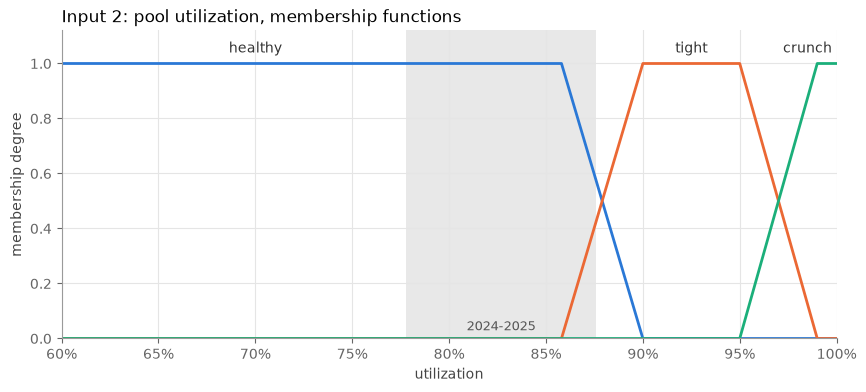

In [ ]:
UTIL = utilization_variable(util_d)
print("breakpoints:", {t: [f"{x:.1%}" for x in pts] for t, pts in UTIL.terms.items()})
print(f"membership sum over the universe: min {UTIL.coverage().min():.3f}, max {UTIL.coverage().max():.3f}")
for d in ["2025-12-01", "2026-01-01", "2026-02-01"]:
    print(f"{d[:7]} ({util[d]:.1%}):", {t: round(x, 2) for t, x in UTIL.memberships(util[d]).items()})

plot_memberships(UTIL, "Input 2: pool utilization, membership functions", "utilization",
                 band=(util.loc[:"2025-12"].min(), util.loc[:"2025-12"].max()), band_label="2024-2025",
                 label_x={"healthy": 0.70, "crunch": 0.985}, xlim=(0.6, 1.0))
plt.show()

### 2.4 Rent coverage (stylized)

**What it measures.** The share of the expected rent actually paid to token holders: 100% means rent arrives as
promised, 0% means the property produces no income.

**Why stylized.** RealT's public API went offline after the liquidation and no rent time series is published. The
series is built from documented dates: rent escrow from July 2025, distributions largely halted by the end of
2025, formal suspension in February 2026 (Outlier Media, BridgeDetroit, Lofty). The path between those dates is an
assumption: linear fall from 100% in June 2025 to 20% in December 2025, 10% in January 2026, zero after.
**Limitation:** because the timing of the fall is set by the scenario, the project shows how the controller reacts
to falling rent; it cannot prove that rent fell before the pool emptied. Code: `rent_coverage_stylized`.

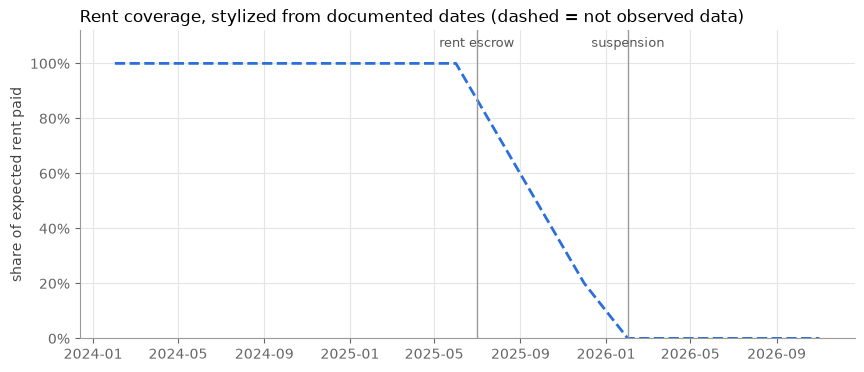

In [ ]:
rent = rent_coverage_stylized()

fig, ax = plt.subplots()
ax.plot(rent.index, rent, color=LINE, lw=2, ls="--")
for d, label in [("2025-07-01", "rent escrow"), ("2026-02-01", "suspension")]:
    ax.axvline(pd.Timestamp(d), color="#9a9a9a", lw=1)
    ax.text(pd.Timestamp(d), 1.06, label, ha="center", color="#555555", fontsize=9)
pct_axis(ax.yaxis)
ax.set_ylim(0, 1.12)
ax.set_ylabel("share of expected rent paid")
ax.set_title("Rent coverage, stylized from documented dates (dashed = not observed data)", loc="left")
plt.show()

**Fuzzy terms.** With no historical distribution to anchor them, the breakpoints are stated hypotheses:

| Term | Breakpoints | Reading |
| --- | --- | --- |
| low | 0, 0, 30%, 60% | below 30% the asset is not producing income |
| partial | 30%, 60%, 80%, 95% | a partial payer |
| full | 80%, 95%, 100%, 100% | from 95% rent is paid as expected |

membership sum over the universe: min 1.000, max 1.000
2025-08 (73%): {'low': 0.0, 'partial': 1.0, 'full': 0.0}
2025-10 (47%): {'low': 0.44, 'partial': 0.56, 'full': 0.0}
2025-12 (20%): {'low': 1.0, 'partial': 0.0, 'full': 0.0}


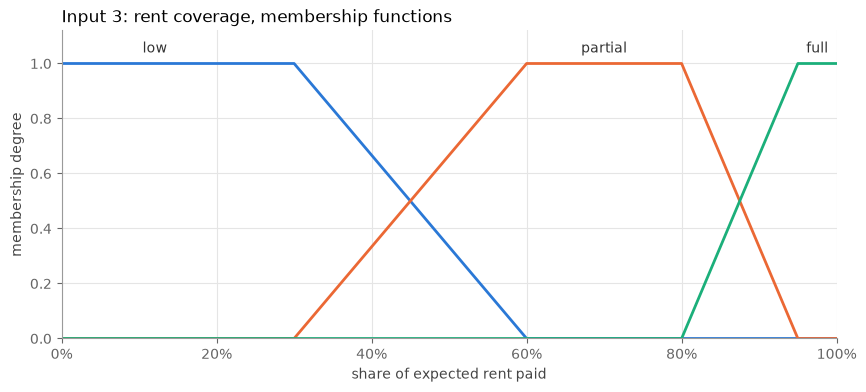

In [ ]:
RENT = rent_variable()
print(f"membership sum over the universe: min {RENT.coverage().min():.3f}, max {RENT.coverage().max():.3f}")
for d in ["2025-08-01", "2025-10-01", "2025-12-01"]:
    print(f"{d[:7]} ({rent[d]:.0%}):", {t: round(x, 2) for t, x in RENT.memberships(rent[d]).items()})

plot_memberships(RENT, "Input 3: rent coverage, membership functions", "share of expected rent paid",
                 label_x={"low": 0.12, "full": 0.975})
plt.show()

### 2.5 Output: max LTV

**What it is.** The largest loan the pool allows per dollar of collateral, set by the controller every month,
between 30% (crisis) and 60% (RealT's fixed value, the benchmark).

**Terms.** Triangles centred on 30% (low), 45% (medium) and 60% (high), each 15 points wide on either side. The
universe runs from 15% to 75% so that, when a single term is active, the centroid (the centre of mass of the output shape, the standard way to turn a fuzzy result back into one number) lands exactly on the term's centre: a calm
market gives exactly 60%, the same as the fixed rule, which keeps the comparison fair. The crisp output is then
clipped to [30%, 60%]. Code: `max_ltv_variable`.

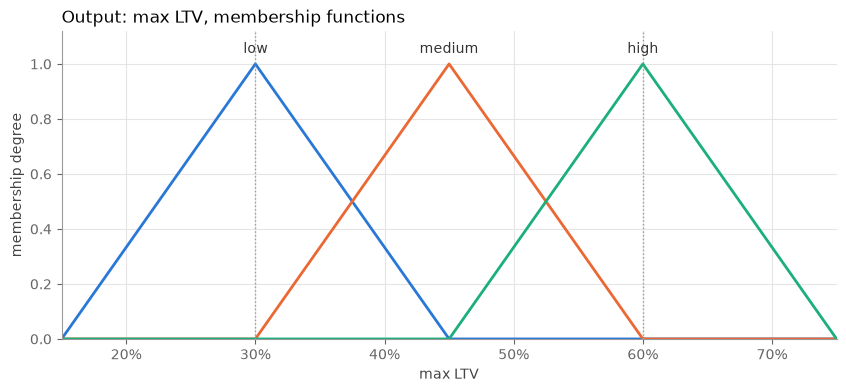

In [ ]:
LTV = max_ltv_variable()
fig, ax = plot_memberships(LTV, "Output: max LTV, membership functions", "max LTV")
for x in (LTV_MIN, LTV_MAX):
    ax.axvline(x, color="#9a9a9a", lw=1, ls=":")
plt.show()

## 3. Rule base

**The principle.** Each input term gets a severity score: how much it worsens the risk of lending. The rule for each
combination adds the three scores and maps the total to an output term. This keeps the 27 rules consistent with one
idea instead of 27 separate judgements.

| Input | Term → severity | Why |
| --- | --- | --- |
| Volatility | low 0 · medium 1 · high 2 | medium is the normal market (it contains the median), so it scores little |
| Utilization | healthy 0 · tight 2 · crunch 3 | an empty pool means lenders cannot withdraw: severe on its own |
| Rent coverage | full 0 · partial 2 · low 3 | an asset that stopped paying rent is a severe signal on its own |

| Total severity | Output term | Max LTV |
| --- | --- | --- |
| 0 to 1 | high | 60% (same as RealT's fixed rule) |
| 2 to 3 | medium | 45% |
| 4 or more | low | 30% |

**Consequences of the principle.** A calm market (medium volatility, healthy pool, full rent) scores 1 and keeps
the 60% of the fixed rule. High volatility alone scores 3: the LTV drops to 45%. A crunch alone or rent alone scores
4: the LTV drops to 30%, because a problem in the pool or in the rent is not offset by a calm price.

The tables below list all 27 rules, one table per rent level (rows: volatility; columns: utilization). Code:
`adaptive_ltv/controller.py` (`build_rules`).

In [ ]:
rules = pd.DataFrame(build_rules(), columns=["volatility", "utilization", "rent_coverage", "max_ltv"])
print(f"{len(rules)} rules, {rules[['volatility', 'utilization', 'rent_coverage']].drop_duplicates().shape[0]} distinct input combinations")
for r in ["full", "partial", "low"]:
    t = (rules[rules.rent_coverage == r]
         .pivot(index="volatility", columns="utilization", values="max_ltv")
         .loc[["low", "medium", "high"], ["healthy", "tight", "crunch"]])
    print(f"\nRent coverage = {r}")
    print(t.to_string())

27 rules, 27 distinct input combinations

Rent coverage = full
utilization healthy   tight  crunch
volatility                         
low            high  medium  medium
medium         high  medium     low
high         medium     low     low

Rent coverage = partial
utilization healthy tight crunch
volatility                      
low          medium   low    low
medium       medium   low    low
high            low   low    low

Rent coverage = low
utilization healthy tight crunch
volatility                      
low          medium   low    low
medium          low   low    low
high            low   low    low


**Coherence check.** Making any single input worse never raises the max LTV. This is tested in
`tests/test_controller.py` over a grid of inputs. One known effect of Mamdani inference appears there: where two
output terms overlap, the centroid can move up by a fraction of a point (measured maximum: 0.3 point of LTV). The
test allows 0.5 point for that effect.

### 3.1 How the controller decides (Mamdani inference)

For every month the controller runs four steps. The example below uses October 2025, when RealT's rent was already
failing but the pool still had cash.

1. **Fuzzification:** each input number becomes degrees of membership in its terms.
2. **Rule activation:** each rule is active to the degree of its weakest condition (the minimum of its three degrees).
3. **Aggregation:** each active rule cuts its output term at its activation level; the cut shapes are overlaid
   (maximum), giving one combined shape over the LTV axis.
4. **Defuzzification:** the centroid of that shape is the max LTV, kept between 30% and 60%.

Inputs 2025-10: volatility 5.8%, utilization 87.6%, rent coverage 47%
      volatility: {'medium': 1.0}
     utilization: {'healthy': 0.57, 'tight': 0.43}
   rent_coverage: {'low': 0.44, 'partial': 0.56}
Active rules:
  IF volatility is medium AND utilization is healthy AND rent is partial THEN max LTV is medium   (strength 0.56)
  IF volatility is medium AND utilization is healthy AND rent is low THEN max LTV is low   (strength 0.44)
  IF volatility is medium AND utilization is tight AND rent is partial THEN max LTV is low   (strength 0.43)
  IF volatility is medium AND utilization is tight AND rent is low THEN max LTV is low   (strength 0.43)
Max LTV = 38.2%


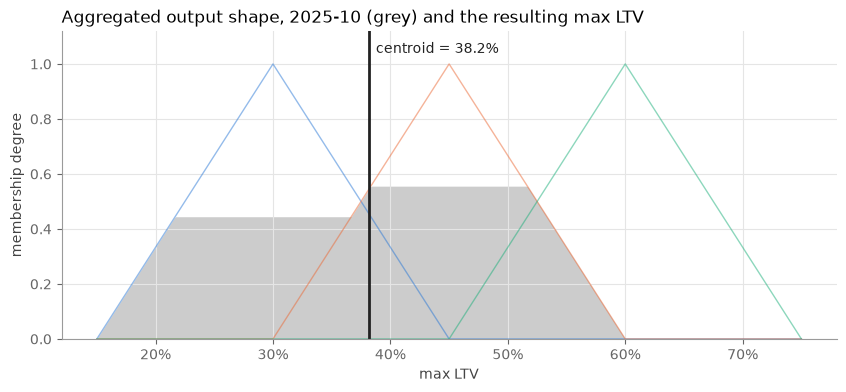

In [ ]:
CTRL = FuzzyLTVController(VOL, UTIL, RENT, LTV)

month = "2025-10-01"
d = CTRL.decide(vol[month], util[month], rent[month])
print(f"Inputs {month[:7]}: volatility {vol[month]:.1%}, utilization {util[month]:.1%}, rent coverage {rent[month]:.0%}")
for name, degrees in d.memberships.items():
    print(f"  {name:>14}:", {t: round(x, 2) for t, x in degrees.items() if x > 0})
print("Active rules:")
for (v, u, r, out), s in sorted(d.activations, key=lambda a: -a[1]):
    if s > 0:
        print(f"  IF volatility is {v} AND utilization is {u} AND rent is {r} THEN max LTV is {out}   (strength {s:.2f})")
print(f"Max LTV = {d.max_ltv:.1%}")

fig, ax = plt.subplots()
for (term, mf), color in zip(LTV.mf.items(), ["#2a78d6", "#eb6834", "#1baf7a"]):
    ax.plot(LTV.universe, mf, color=color, lw=1, alpha=0.5)
ax.fill_between(LTV.universe, d.aggregated, color="#9a9a9a", alpha=0.5, lw=0)
ax.axvline(d.max_ltv, color="#222222", lw=2)
ax.text(d.max_ltv + 0.006, 1.04, f"centroid = {d.max_ltv:.1%}", ha="left", fontsize=10, color="#222222")
pct_axis(ax.xaxis)
ax.set_ylim(0, 1.12)
ax.set_xlabel("max LTV")
ax.set_ylabel("membership degree")
ax.set_title(f"Aggregated output shape, {month[:7]} (grey) and the resulting max LTV", loc="left")
plt.show()

### 3.2 Preview: the controller on the real RealT period (no feedback yet)

Before building the market simulation, the controller can be applied to the observed signals of 2024-2026 month by
month. This is **open loop**: the decisions do not change the market here. The closed loop comes in sections 5 and 6.

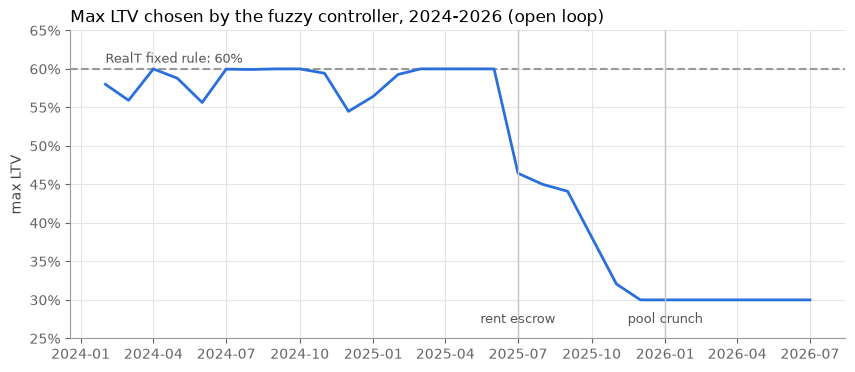

             vol utilization rent_coverage max_ltv
2025-05-01  5.7%       84.1%          100%   60.0%
2025-06-01  6.0%       85.6%          100%   60.0%
2025-07-01  5.7%       87.2%           87%   46.4%
2025-08-01  5.8%       85.4%           73%   45.0%
2025-09-01  6.0%       86.0%           60%   44.1%
2025-10-01  5.8%       87.6%           47%   38.2%
2025-11-01  5.8%       86.0%           33%   32.1%
2025-12-01  5.7%       85.7%           20%   30.0%
2026-01-01  4.9%       93.3%           10%   30.0%
2026-02-01  5.1%       99.4%            0%   30.0%


In [ ]:
signals = pd.concat([vol, util, rent], axis=1).dropna()
signals["max_ltv"] = [CTRL(*row) for row in signals[["vol", "utilization", "rent_coverage"]].values]

fig, ax = plt.subplots()
ax.axhline(LTV_MAX, color="#9a9a9a", lw=1.5, ls="--")
ax.text(signals.index.min(), LTV_MAX + 0.008, "RealT fixed rule: 60%", color="#555555", fontsize=9)
ax.plot(signals.index, signals["max_ltv"], color=LINE, lw=2)
for dte, label in [("2025-07-01", "rent escrow"), ("2026-01-01", "pool crunch")]:
    ax.axvline(pd.Timestamp(dte), color="#c4c4c4", lw=1)
    ax.text(pd.Timestamp(dte), 0.27, label, ha="center", fontsize=9, color="#555555")
pct_axis(ax.yaxis)
ax.set_ylim(0.25, 0.65)
ax.set_ylabel("max LTV")
ax.set_title("Max LTV chosen by the fuzzy controller, 2024-2026 (open loop)", loc="left")
plt.show()

print(signals.loc["2025-05":"2026-02"].assign(
    vol=lambda df: df.vol.map("{:.1%}".format), utilization=lambda df: df.utilization.map("{:.1%}".format),
    rent_coverage=lambda df: df.rent_coverage.map("{:.0%}".format), max_ltv=lambda df: df.max_ltv.map("{:.1%}".format)
).to_string())

**Reading.** In 2024 the limit dips to 55-58% in a few months: utilization rose slightly above its median (85.8%),
which makes it partly "tight". From March 2025 the controller keeps 60% until June 2025, then cuts the limit as rent
falls: 46% in July, 38% in
October, 30% from December 2025, one month before the pool ran out of cash in January 2026. Volatility stayed
"medium" throughout and played no part.

**Caution.** The early cut comes from the rent series, which is stylized: its timing was set from documented dates,
not measured. What this preview shows is how the rules react to falling rent, not that rent data would have given
this warning in practice. In the 2007-2011 crash, by contrast, only volatility reacts: it lowers the limit to 45% at
most, and only after prices had already been falling for about a year (section 2.1). Both points are tested in the
simulations.